# SalesVision — Sales Forecasting Experiments
## 1. Project introduction and objectives
**Sales Forecasting Using Python · Business Analytics · Review 3**

This notebook executes the same reusable Python services as the Streamlit application. It investigates real UCI Online Retail net revenue, compares Statsmodels ARIMA/SARIMAX and official Prophet on a common chronological holdout, retrains each on full history, and exports actual results. Gemini optionally explains computed analytics; it never supplies numerical predictions.

Run cells in order. Included outputs are from an actual local Python 3.12 execution. Hosted Google Colab upload/Drive branches are supplied for portability and have not been claimed as remotely executed.

## 2. Environment setup, project upload and optional Google Drive
Locally, run this notebook from the project environment or use `python scripts/execute_notebook.py`. In Colab, upload this `.ipynb`, then run the following cell. If requested, upload the project ZIP produced by `python scripts/package_project.py`. The ZIP includes shared services, pinned requirements and the real derived sample.

For Drive instead, first put the unpacked project under `MyDrive/sales-forecasting-system`, set `USE_GOOGLE_DRIVE = True`, and update `DRIVE_PROJECT_DIRECTORY` if needed. Use a Python 3.12 runtime; Python 3.11 is also accepted by this notebook. On an already-used Colab runtime, restart if dependency installation reports that loaded packages need restarting. No API key is embedded in the notebook.

In [1]:
import io
import json
import os
import subprocess
import sys
import zipfile
from pathlib import Path

try:
    import google.colab
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

USE_GOOGLE_DRIVE = False
DRIVE_PROJECT_DIRECTORY = Path('/content/drive/MyDrive/sales-forecasting-system')
if IS_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

candidates = [DRIVE_PROJECT_DIRECTORY] if IS_COLAB and USE_GOOGLE_DRIVE else [Path.cwd(), Path.cwd().parent, Path('/content/sales-forecasting-system')]
ROOT = next((path.resolve() for path in candidates if (path / 'src/experiments/retail_experiment.py').is_file()), None)
if ROOT is None and IS_COLAB and not USE_GOOGLE_DRIVE:
    from google.colab import files
    uploaded = files.upload()
    project_archives = [(name, content) for name, content in uploaded.items() if name.lower().endswith('.zip')]
    if len(project_archives) != 1:
        raise RuntimeError('Upload exactly one SalesVision project ZIP.')
    extraction_root = Path('/content').resolve()
    with zipfile.ZipFile(io.BytesIO(project_archives[0][1])) as archive:
        for member in archive.infolist():
            destination = (extraction_root / member.filename).resolve()
            if not destination.is_relative_to(extraction_root):
                raise RuntimeError('The archive contains an invalid extraction path.')
        archive.extractall(extraction_root)
    ROOT = Path('/content/sales-forecasting-system')
if ROOT is None or not (ROOT / 'requirements.txt').is_file():
    raise RuntimeError('Locate the complete unpacked SalesVision project before continuing.')
if not (3, 11) <= sys.version_info[:2] <= (3, 12):
    raise RuntimeError('Use Python 3.12 (or a Python 3.11 Colab runtime) for the pinned dependencies.')
if IS_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(ROOT / 'requirements.txt')], cwd=ROOT)
sys.path.insert(0, str(ROOT))
OUTPUT_DIRECTORY = ROOT / 'outputs/experiments/uci_daily_notebook'
print(f'Python {sys.version.split()[0]}; Colab={IS_COLAB}; project={ROOT}')
print(f'Generated notebook artifacts: {OUTPUT_DIRECTORY}')


Python 3.12.10; Colab=False; project=D:\Project\MinorProject\sales-forecasting-system
Generated notebook artifacts: D:\Project\MinorProject\sales-forecasting-system\outputs\experiments\uci_daily_notebook


## 3. Dataset acquisition, provenance and description
Source: [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), Chen, D. (2015), DOI **10.24432/C5BW33**, **CC BY 4.0**. The original workbook has 541,909 invoice lines from December 2010 to December 2011. `scripts/fetch_uci_data.py` reproducibly derives recorded daily GBP net revenue as `Quantity × UnitPrice`, retaining refunds/cancellations and exact source duplicates. The included derived file excludes customer identifiers.

Dates without source transactions are absent, not assumed zero. This is a real UK online retailer dataset, not Walmart. Walmart competition data requires legitimate manual acquisition; its weekly observations cannot reveal daily behavior.

In [2]:
import pandas as pd
from IPython.display import Image, Markdown, display
from src.data.loader import load_dataset
from src.experiments.retail_experiment import prepare_uci_dataset, experiment_configurations, benchmark_baselines, experiment_findings, export_experiment
from src.visualization.charts import report_history_figure, report_decomposition_figure, report_evaluation_figure, report_comparison_figure

source_path = ROOT / 'data/sample/uci_online_retail_daily.csv'
if not source_path.is_file():
    subprocess.check_call([sys.executable, str(ROOT / 'scripts/fetch_uci_data.py')], cwd=ROOT)
loaded = load_dataset(source_path)
source_metadata = json.loads(source_path.with_suffix('.metadata.json').read_text(encoding='utf-8'))
display(loaded.frame.head(10))
print(json.dumps({key: source_metadata[key] for key in ['name', 'source_url', 'citation', 'license', 'currency', 'source_rows', 'derived_rows', 'negative_transaction_count', 'exact_source_duplicates']}, indent=2))
print(f'Derived file SHA-256: {loaded.sha256}')


,Date,Sales,Transactions
0,2010-12-01,58635.56,3108
1,2010-12-02,46207.28,2109
2,2010-12-03,45620.46,2202
3,2010-12-05,31383.95,2725
4,2010-12-06,53860.18,3878
5,2010-12-07,45059.05,2963
6,2010-12-08,44189.84,2647
7,2010-12-09,52532.13,2891
8,2010-12-10,57404.91,2758
9,2010-12-12,17240.92,1451


{
  "name": "UCI Online Retail \u2014 recorded daily net revenue",
  "source_url": "https://archive.ics.uci.edu/dataset/352/online+retail",
  "citation": "Chen, D. (2015). Online Retail. UCI Machine Learning Repository. DOI: 10.24432/C5BW33.",
  "license": "CC BY 4.0",
  "currency": "GBP",
  "source_rows": 541909,
  "derived_rows": 305,
  "negative_transaction_count": 9290,
  "exact_source_duplicates": 5268
}
Derived file SHA-256: d9b2e2d967602d1aa41fcdb48701ba5d5bc07c4bed056ce21e8f23eebaaeef5c


## 4. Validation, explicit cleaning and continuous calendar
Use the application pipeline: reject invalid dates/sales, retain source duplicates and negative net revenue, sum at daily frequency, and explicitly forward-fill unknown days using only prior values. The model-input series is separate from original observations. Holdout scoring excludes every unknown/imputed target. No full-history outlier rule removes or clips data; IQR flags are diagnostic only.

In [3]:
from dataclasses import asdict
dataset = prepare_uci_dataset(ROOT)
assert dataset.model_ready
assert dataset.frequency == 'D'
assert dataset.observed_mask.sum() == len(loaded.frame)
calendar = pd.DataFrame({'observed_sales': dataset.observed_series, 'model_input': dataset.series, 'is_observed': dataset.observed_mask})
display(pd.DataFrame(dataset.operations))
display(calendar.head(14))
display(pd.DataFrame([asdict(dataset.quality)]).drop(columns='missing_by_column'))
print(f'{len(dataset.series)} calendar days; {int(dataset.observed_mask.sum())} genuine observed days; {len(dataset.missing_periods)} unknown days.')
print(f'Dataset fingerprint: {dataset.fingerprint}')


,operation,affected_rows,detail
0,Convert dates and normalize to calendar date,305,Source: Date; format: mixed; day-first: False;...
1,Convert sales to numeric,305,Source: Sales; non-finite values are invalid.
2,Invalid-record policy,0,Detected 0; retained by explicit policy.
3,Missing-sales policy,0,Detected 0; retained by explicit policy.
4,Negative-sales policy,0,Detected 1; retained by explicit policy.
5,Duplicate policy,0,Detected 0; retained by explicit policy.
6,Chronological sorting,305,Stable date sort; source-row identifiers retai...
7,Aggregate sales,305,sum into 374 D periods; periods with any missi...
8,Build continuous calendar index,69,69 absent periods and 0 incomplete periods det...
9,Missing-period policy,69,Policy: ffill. Original observations and imput...


,observed_sales,model_input,is_observed
date,,,
2010-12-01,58635.56,58635.56,True
2010-12-02,46207.28,46207.28,True
2010-12-03,45620.46,45620.46,True
2010-12-04,NaN,45620.46,False
2010-12-05,31383.95,31383.95,True
2010-12-06,53860.18,53860.18,True
2010-12-07,45059.05,45059.05,True
2010-12-08,44189.84,44189.84,True
2010-12-09,52532.13,52532.13,True


,rows,columns,duplicates,invalid_dates,missing_dates,invalid_sales,missing_sales,negative_sales,zero_sales,suggested_frequency
0,305,3,0,0,0,0,0,1,0,D


374 calendar days; 305 genuine observed days; 69 unknown days.
Dataset fingerprint: c40c7a2d953a48c7c668e979f4b87a011afccf2f6d969a037936b58f9d2adf02


## 5. Exploratory data analysis
Statistics and totals below use original observed revenue, not forward-filled model inputs. Monthly rollups may contain unknown days and incomplete boundary months. First-to-latest growth describes endpoint change; it is not a causal trend estimate or evidence of year-over-year growth.

,total,mean,median,std,min,max,growth_pct,observations,calendar_periods,missing_periods,zero_periods,negative_periods,start,end
0,9747747.934,31959.829292,27978.41,17414.261664,-1566.23,112141.11,-45.201291,305,374,69,0,1,2010-12-01T00:00:00,2011-12-09T00:00:00


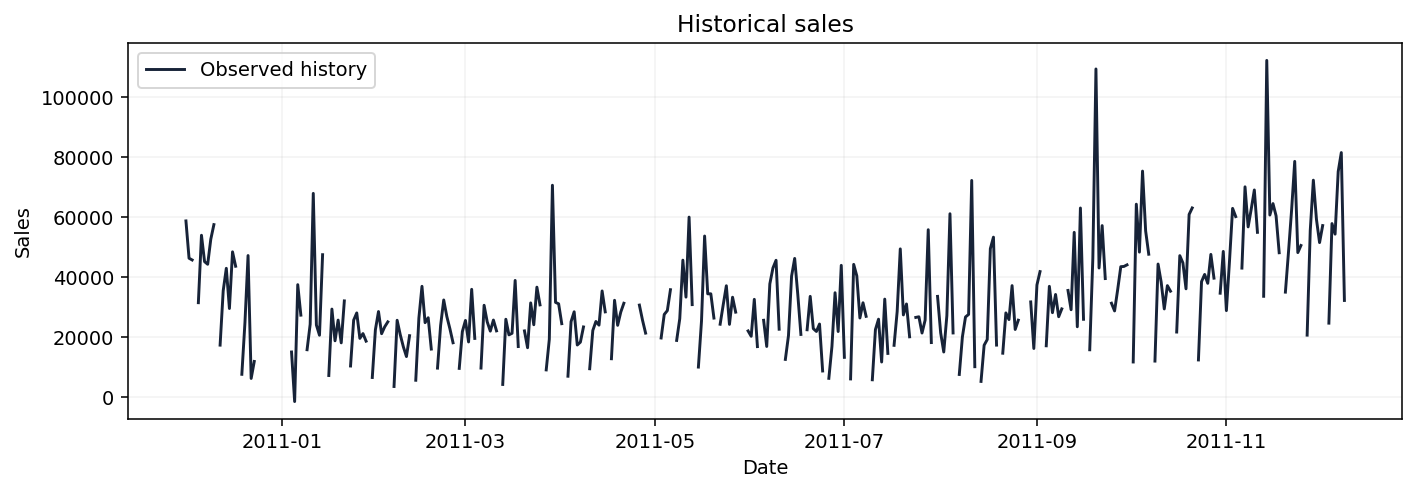

,date,sales,year,month,month_name
0,2010-12-01,748957.020,2010,12,Dec
1,2011-01-01,560000.260,2011,1,Jan
2,2011-02-01,498062.650,2011,2,Feb
3,2011-03-01,683267.080,2011,3,Mar
4,2011-04-01,493207.121,2011,4,Apr
5,2011-05-01,723333.510,2011,5,May
6,2011-06-01,691123.120,2011,6,Jun
7,2011-07-01,681300.111,2011,7,Jul
8,2011-08-01,682680.510,2011,8,Aug
9,2011-09-01,1019687.622,2011,9,Sep


,weekday_number,mean,total,observations,weekday
0,0,33800.200660,1588609.431,47,Monday
1,1,37811.207519,1966182.791,52,Tuesday
2,2,32719.754906,1734147.010,53,Wednesday
3,3,39858.849057,2112519.000,53,Thursday
4,4,30812.216220,1540610.811,50,Friday
5,5,NaN,NaN,0,Saturday
6,6,16113.577820,805678.891,50,Sunday


In [4]:
from src.features.time_features import statistical_summary, monthly_comparison, weekday_summary
display(pd.DataFrame([statistical_summary(dataset.observed_series)]).drop(columns='growth_definition'))
display(Image(report_history_figure(dataset.observed_series)))
display(monthly_comparison(dataset.observed_series))
display(weekday_summary(dataset.observed_series, dataset.frequency))


## 6. Seasonal decomposition
Robust STL uses a seven-observation cycle on the explicitly filled daily modelling series. Seasonal strength and amplitude are computed, not invented. Missing-date assumptions affect these descriptive components. About one year of history does not justify yearly Prophet seasonality or a proven causal holiday effect.

The estimated repeating component is moderate at a period of 7 observations. STL seasonal strength is 0.386; the 5th–95th percentile seasonal amplitude is 26,747.51 sales units. Residual standard deviation is 9,898.85. This is a descriptive decomposition, not proof of a causal holiday effect or a guarantee of future seasonality.


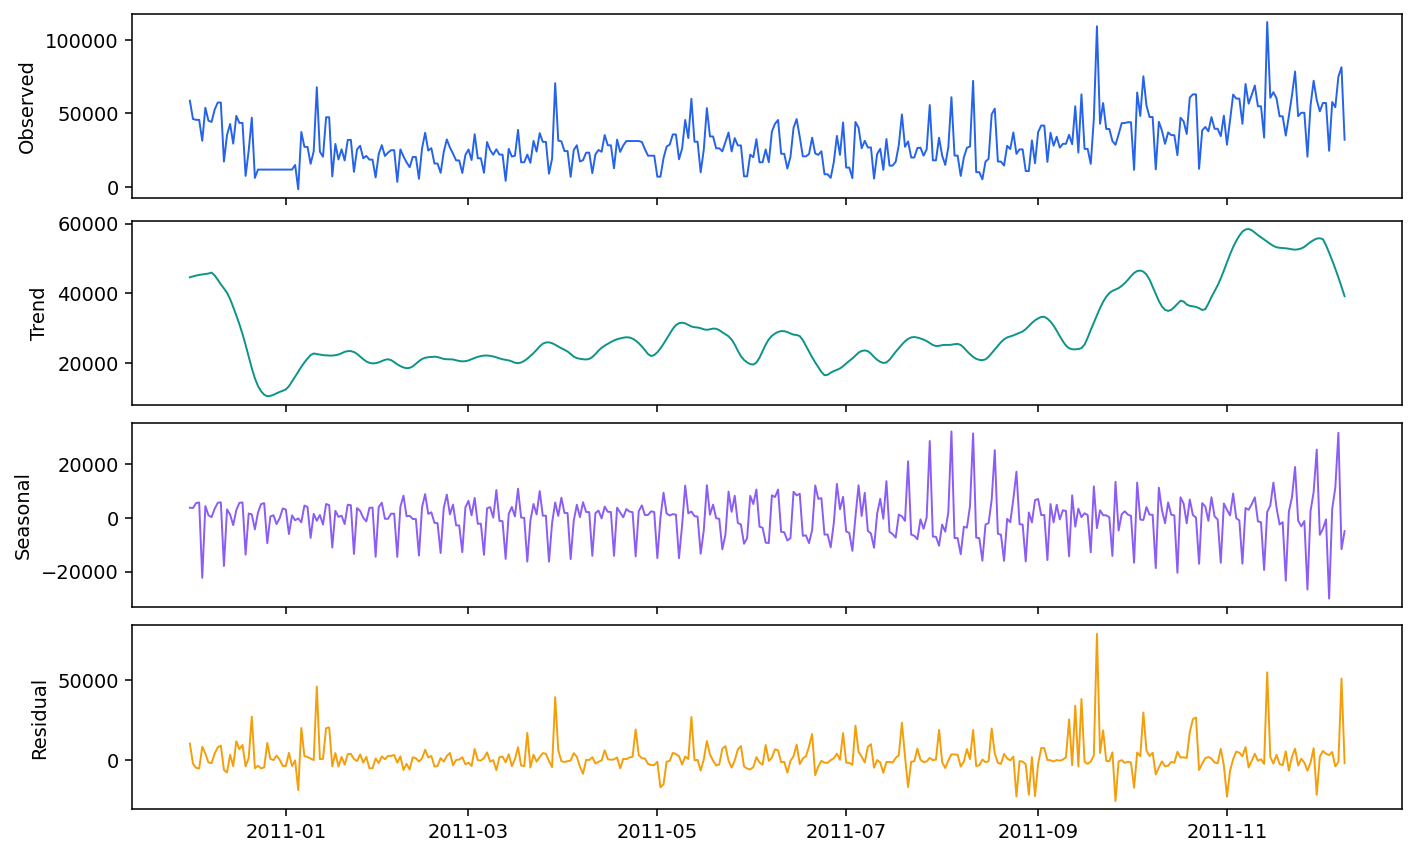

,observed,trend,seasonal,residual
date,,,,
2010-12-01,58635.56,44624.623743,3823.398221,10187.538036
2010-12-02,46207.28,44880.591720,3713.191676,-2386.503396
2010-12-03,45620.46,45115.843768,5547.420950,-5042.804719
2010-12-04,45620.46,45302.748782,5785.005953,-5467.294735
2010-12-05,31383.95,45436.612755,-22292.153290,8239.490534


In [5]:
from src.features.time_features import seasonal_decomposition
seasonal = seasonal_decomposition(dataset.series, 7)
print(seasonal.explanation)
display(Image(report_decomposition_figure(seasonal.components)))
display(seasonal.components.head())


## 7. Chronological design and shared model training
Prespecified settings: ARIMA(1,1,1); SARIMAX(1,1,1)(0,1,1,7); additive Prophet with within-week seasonality, no yearly or intraday terms, changepoint prior 0.05. The same final 30 calendar days are withheld for all three models. Numerical scaling is fitted on training history only. The three earlier 14-day rolling-origin folds remain inside the training partition. Seed is 42; intervals are 95%. No parameters are selected by repeatedly inspecting final holdout errors.

The following single `evaluate_models` call trains and evaluates all three through the exact application service. Sections 8–10 inspect their separately recorded fitted results.

In [6]:
from src.evaluation.backtesting import chronological_split
from src.evaluation.model_comparison import evaluate_models
HOLDOUT = 30
HORIZON = 30
configurations = experiment_configurations()
train, test = chronological_split(dataset.series, HOLDOUT)
assert train.index[-1] < test.index[0]
display(pd.DataFrame([configuration.to_dict() for configuration in configurations]))
evaluation = evaluate_models(dataset, configurations, HOLDOUT, ranking_metric='RMSE', backtest_folds=3, backtest_horizon=14)
assert len(evaluation.comparison) == 3 and evaluation.comparison['Status'].eq('success').all()
print(f'Training ends {evaluation.training_end}; shared holdout {evaluation.test_start} to {evaluation.test_end}.')
print(f'Scored genuine targets: {int(dataset.observed_series.iloc[-HOLDOUT:].notna().sum())} of {HOLDOUT} calendar days.')


,name,order,seasonal_order,trend,interval_width,maxiter,yearly_seasonality,weekly_seasonality,daily_seasonality,seasonality_mode,changepoint_prior_scale,use_holidays,regressor_columns,seed
0,ARIMA,"(1, 1, 1)","(0, 1, 1, 7)",None,0.95,150,None,None,False,additive,0.05,False,(),42
1,SARIMA,"(1, 1, 1)","(0, 1, 1, 7)",None,0.95,150,None,None,False,additive,0.05,False,(),42
2,Prophet,"(1, 1, 1)","(0, 1, 1, 7)",None,0.95,150,False,True,False,additive,0.05,False,(),42


D:\Project\MinorProject\sales-forecasting-system\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
21:56:11 - cmdstanpy - INFO - Chain [1] start processing


21:56:11 - cmdstanpy - INFO - Chain [1] done processing


21:56:12 - cmdstanpy - INFO - Chain [1] start processing


21:56:12 - cmdstanpy - INFO - Chain [1] done processing


21:56:12 - cmdstanpy - INFO - Chain [1] start processing


21:56:12 - cmdstanpy - INFO - Chain [1] done processing


21:56:12 - cmdstanpy - INFO - Chain [1] start processing


21:56:12 - cmdstanpy - INFO - Chain [1] done processing


Training ends 2011-11-09T00:00:00; shared holdout 2011-11-10T00:00:00 to 2011-12-09T00:00:00.
Scored genuine targets: 26 of 30 calendar days.


## 8. ARIMA results
Statsmodels ARIMA models autoregression and moving-average errors after differencing. Its output is a genuine fitted forecast, not a generated example or AI prediction. Any convergence retry is recorded.

In [7]:
display(evaluation.comparison.loc[evaluation.comparison['Model'].eq('ARIMA')])
display(evaluation.predictions['ARIMA'].head(10))
print(evaluation.summaries['ARIMA'])
print('Recorded warnings:', evaluation.warnings['ARIMA'])


,Model,MAE,RMSE,MAPE,sMAPE,Bias,Training Time,Scored Observations,MAPE Observations,Zero Actuals,Status,Error
0,ARIMA,14384.500051,19529.03145,29.657948,26.745593,-5150.079016,0.033647,26,26,0,success,


,date,prediction,lower,upper,actual,is_observed,error,absolute_error,percentage_error
0,2011-11-10,52821.091638,26978.221392,78663.961884,68956.24,True,-16135.148362,16135.148362,23.399113
1,2011-11-11,51413.472592,24767.385296,78059.559889,54835.51,True,-3422.037408,3422.037408,6.240550
2,2011-11-12,51210.841910,24308.046486,78113.637334,NaN,False,NaN,NaN,NaN
3,2011-11-13,51181.672659,24076.427849,78286.917468,33520.22,True,17661.452659,17661.452659,52.688952
4,2011-11-14,51177.473664,23878.210038,78476.737289,112141.11,True,-60963.636336,60963.636336,54.363325
5,2011-11-15,51176.869207,23685.936697,78667.801717,60594.23,True,-9417.360793,9417.360793,15.541679
6,2011-11-16,51176.782193,23495.647912,78857.916475,64408.70,True,-13231.917807,13231.917807,20.543681
7,2011-11-17,51176.769668,23306.751648,79046.787687,60329.72,True,-9152.950332,9152.950332,15.171545
8,2011-11-18,51176.767864,23119.140503,79234.395226,48031.80,True,3144.967864,3144.967864,6.547679
9,2011-11-19,51176.767605,22932.777469,79420.757740,NaN,False,NaN,NaN,NaN


Sales were scaled by 15088.4 for optimization; forecasts are restored to original units.
                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                  344
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -441.126
Date:                Mon, 16 Nov 2026   AIC                            888.252
Time:                        21:56:11   BIC                            899.765
Sample:                    12-01-2010   HQIC                           892.838
                         - 11-09-2011                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1440      0.064      2.256      0.024       0.019       0.269
ma.L1         -0.8927      0.031    -28.95

## 9. SARIMA / SARIMAX results
Statsmodels SARIMAX adds the seven-day seasonal differencing/error structure. No future covariates are fabricated; this experiment has no regressors or holiday calendar. Supply genuinely known-at-origin values before enabling those features.

In [8]:
display(evaluation.comparison.loc[evaluation.comparison['Model'].eq('SARIMA')])
display(evaluation.predictions['SARIMA'].head(10))
print(evaluation.summaries['SARIMA'])
print('Recorded warnings:', evaluation.warnings['SARIMA'])


,Model,MAE,RMSE,MAPE,sMAPE,Bias,Training Time,Scored Observations,MAPE Observations,Zero Actuals,Status,Error
1,SARIMA,12076.295975,16669.56,26.449799,22.147125,4013.102018,0.123381,26,26,0,success,


,date,prediction,lower,upper,actual,is_observed,error,absolute_error,percentage_error
0,2011-11-10,67646.315232,45166.861289,90125.769175,68956.24,True,-1309.924768,1309.924768,1.899646
1,2011-11-11,55979.979909,32587.774114,79372.185703,54835.51,True,1144.469909,1144.469909,2.087096
2,2011-11-12,55880.345358,32081.517417,79679.173300,NaN,False,NaN,NaN,NaN
3,2011-11-13,40609.169998,16458.460424,64759.879573,33520.22,True,7088.949998,7088.949998,21.148280
4,2011-11-14,58419.974249,33928.385704,82911.562794,112141.11,True,-53721.135751,53721.135751,47.904944
5,2011-11-15,60801.102463,35974.075735,85628.129190,60594.23,True,206.872463,206.872463,0.341406
6,2011-11-16,58416.189623,33258.293174,83574.086073,64408.70,True,-5992.510377,5992.510377,9.303883
7,2011-11-17,68744.185754,42824.945993,94663.425514,60329.72,True,8414.465754,8414.465754,13.947464
8,2011-11-18,57767.361840,31427.029092,84107.694588,48031.80,True,9735.561840,9735.561840,20.268992
9,2011-11-19,57757.751149,31037.580263,84477.922035,NaN,False,NaN,NaN,NaN


SARIMAX implementation; sales scaled by 15088.4. Regressor scaling learned only from training data. Forecasts restored to original units.
                                     SARIMAX Results                                     
Dep. Variable:                             sales   No. Observations:                  344
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 7)   Log Likelihood                -391.377
Date:                           Mon, 16 Nov 2026   AIC                            790.753
Time:                                   21:56:11   BIC                            806.022
Sample:                               12-01-2010   HQIC                           796.840
                                    - 11-09-2011                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------

## 10. Prophet results
The official Prophet package fits piecewise trend and supported additive within-week seasonality. Yearly terms are disabled because training spans less than two years; intraday terms are not identifiable from daily aggregates. Its seeded 500-draw predictive simulation supplies period intervals, not guarantees.

In [9]:
display(evaluation.comparison.loc[evaluation.comparison['Model'].eq('Prophet')])
display(evaluation.predictions['Prophet'].head(10))
print(evaluation.summaries['Prophet'])
print('Recorded warnings:', evaluation.warnings['Prophet'])


,Model,MAE,RMSE,MAPE,sMAPE,Bias,Training Time,Scored Observations,MAPE Observations,Zero Actuals,Status,Error
2,Prophet,12312.632984,17955.768434,21.492457,22.14703,-7436.18676,0.153037,26,26,0,success,


,date,prediction,lower,upper,component_trend,component_additive_terms,component_weekly,component_multiplicative_terms,actual,is_observed,error,absolute_error,percentage_error
0,2011-11-10,54296.364119,31432.571519,77218.599080,45897.784452,8398.579667,8398.579667,0.0,68956.24,True,-14659.875881,14659.875881,21.259680
1,2011-11-11,45440.514573,19832.242490,68252.238200,46077.485315,-636.970742,-636.970742,0.0,54835.51,True,-9394.995427,9394.995427,17.133050
2,2011-11-12,45568.416849,24060.323834,67360.021037,46257.186178,-688.769330,-688.769330,0.0,NaN,False,NaN,NaN,NaN
3,2011-11-13,32888.905673,8735.043910,54754.462299,46436.887041,-13547.981368,-13547.981368,0.0,33520.22,True,-631.314327,631.314327,1.883384
4,2011-11-14,46242.862662,23173.073100,68678.167645,46616.587904,-373.725242,-373.725242,0.0,112141.11,True,-65898.247338,65898.247338,58.763684
5,2011-11-15,53186.754069,31555.894190,74866.282122,46796.288767,6390.465302,6390.465302,0.0,60594.23,True,-7407.475931,7407.475931,12.224722
6,2011-11-16,47434.391343,22998.119881,70313.851008,46975.989630,458.401713,458.401713,0.0,64408.70,True,-16974.308657,16974.308657,26.354062
7,2011-11-17,55554.270160,30859.326636,77548.579623,47155.690493,8398.579667,8398.579667,0.0,60329.72,True,-4775.449840,4775.449840,7.915584
8,2011-11-18,46698.420614,23055.961897,69592.235338,47335.391356,-636.970742,-636.970742,0.0,48031.80,True,-1333.379386,1333.379386,2.776035
9,2011-11-19,46826.322889,23544.383201,70582.335123,47515.092219,-688.769330,-688.769330,0.0,NaN,False,NaN,NaN,NaN


{
  "package": "prophet",
  "training_observations": 344,
  "yearly_seasonality": false,
  "weekly_seasonality": true,
  "daily_seasonality": false,
  "seasonalities": {
    "weekly": {
      "period": 7,
      "fourier_order": 3,
      "prior_scale": 10.0,
      "mode": "additive",
      "condition_name": null
    }
  },
  "seasonality_mode": "additive",
  "changepoint_prior_scale": 0.05,
  "changepoints": [
    "2010-12-12T00:00:00",
    "2010-12-23T00:00:00",
    "2011-01-03T00:00:00",
    "2011-01-14T00:00:00",
    "2011-01-25T00:00:00",
    "2011-02-05T00:00:00",
    "2011-02-16T00:00:00",
    "2011-02-27T00:00:00",
    "2011-03-10T00:00:00",
    "2011-03-21T00:00:00",
    "2011-04-01T00:00:00",
    "2011-04-12T00:00:00",
    "2011-04-22T00:00:00",
    "2011-05-03T00:00:00",
    "2011-05-14T00:00:00",
    "2011-05-25T00:00:00",
    "2011-06-05T00:00:00",
    "2011-06-16T00:00:00",
    "2011-06-27T00:00:00",
    "2011-07-08T00:00:00",
    "2011-07-19T00:00:00",
    "2011-07-30T00:0

## 11. Metrics, comparison, baselines and rolling-origin evidence
MAE is mean absolute error; RMSE is square-root mean squared error; MAPE excludes zero actuals and uses absolute actual denominators; sMAPE uses `200 × |prediction−actual| / (|actual|+|prediction|)`, with both-zero pairs contributing zero. Bias is `mean(prediction−actual)`, positive for over-forecasting. All metrics exclude unknown targets.

Last-value and seven-day seasonal-naive forecasts use only the training partition and the same observed holdout dates. They benchmark the three-model selection and are not silently added as selectable application models. A more complex model need not beat a naive baseline.

,Model,MAE,RMSE,MAPE,sMAPE,Bias,Training Time,Scored Observations,MAPE Observations,Zero Actuals,Status,Error
0,ARIMA,14384.500051,19529.031450,29.657948,26.745593,-5150.079016,0.033647,26,26,0,success,
1,SARIMA,12076.295975,16669.560000,26.449799,22.147125,4013.102018,0.123381,26,26,0,success,
2,Prophet,12312.632984,17955.768434,21.492457,22.147030,-7436.186760,0.153037,26,26,0,success,


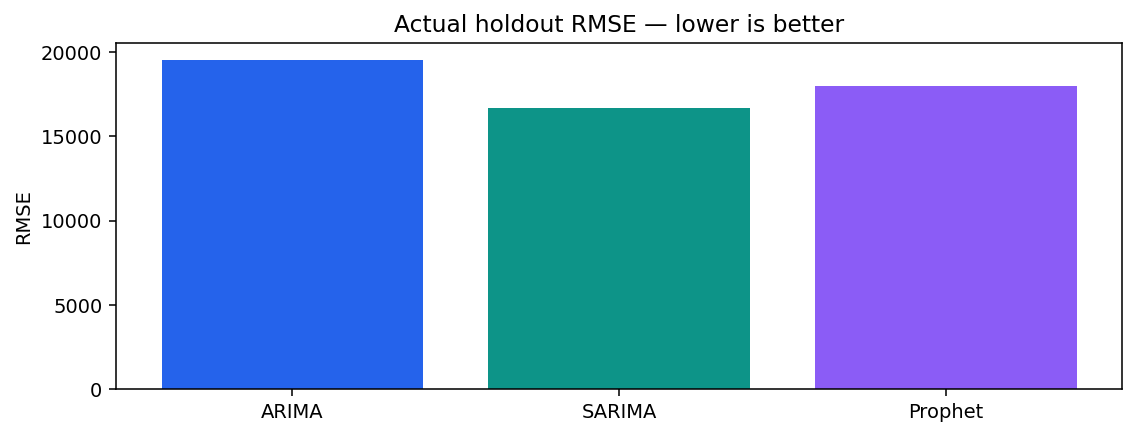

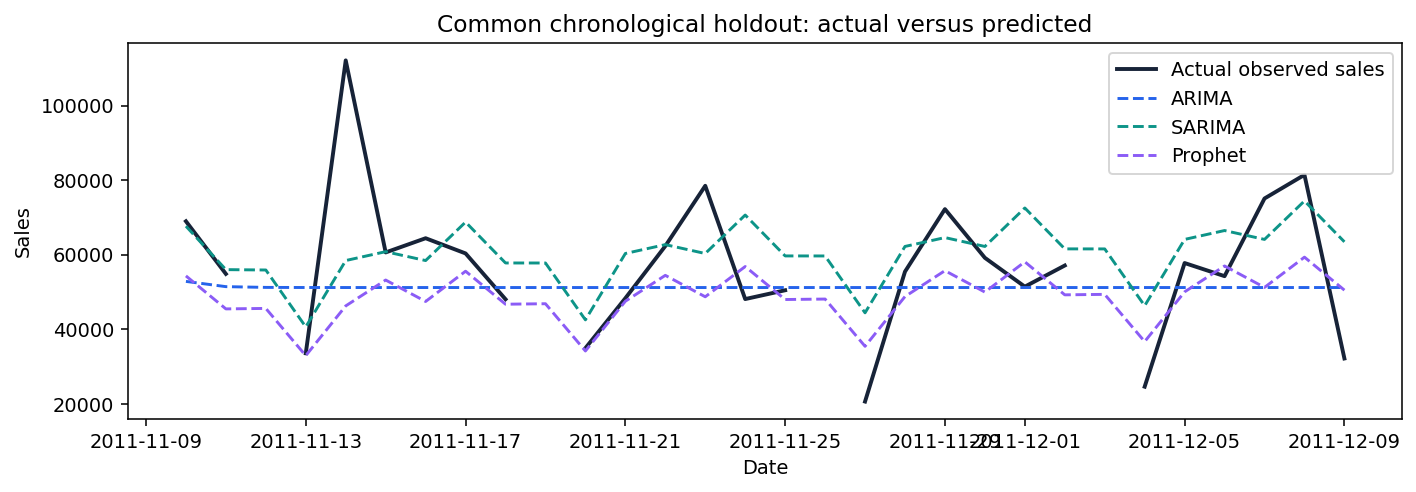

,Baseline,MAE,RMSE,MAPE,sMAPE,Bias,Scored Observations,MAPE Observations,Zero Actuals
0,Last-value naive,15008.011154,19868.399505,36.902579,27.298364,6200.015769,26,26,0
1,Seven-day seasonal naive,12353.890769,15328.037261,26.386335,22.672944,2951.886923,26,26,0


,Model,MAE,RMSE,MAPE,sMAPE,Bias,Scored Observations,MAPE Observations,Zero Actuals,Training Time,Completed Folds,Status,Error
0,ARIMA,12114.007311,15668.914950,39.585831,30.126578,-3594.957265,36,36,0,0.136967,3,success,
1,SARIMA,11131.857553,13738.303832,32.411678,28.063022,-1788.354408,36,36,0,0.613763,3,success,
2,Prophet,11179.009477,14887.998456,26.964381,27.725176,-6767.654433,36,36,0,0.311339,3,success,


,Model,Fold,Train End,Test Start,Test End,MAE,RMSE,MAPE,sMAPE,Bias,Scored Observations,MAPE Observations,Zero Actuals,Training Time,Status
0,ARIMA,1,2011-09-28,2011-09-29,2011-10-12,14295.581244,18161.692565,57.435348,38.186835,-2984.863544,12,12,0,0.041636,success
1,ARIMA,2,2011-10-12,2011-10-13,2011-10-26,9790.794278,13523.905098,38.174666,26.644560,1046.311958,12,12,0,0.045851,success
2,ARIMA,3,2011-10-26,2011-10-27,2011-11-09,12255.646410,14960.000040,23.147478,25.548337,-8846.320209,12,12,0,0.049480,success
3,SARIMA,1,2011-09-28,2011-09-29,2011-10-12,13344.472635,16078.500177,47.316845,36.031350,436.616603,12,12,0,0.198047,success
4,SARIMA,2,2011-10-12,2011-10-13,2011-10-26,8269.116198,10367.469788,25.432841,22.128009,1580.968032,12,12,0,0.241906,success
5,SARIMA,3,2011-10-26,2011-10-27,2011-11-09,11781.983826,14149.925047,24.485349,26.029708,-7382.647861,12,12,0,0.173810,success
6,Prophet,1,2011-09-28,2011-09-29,2011-10-12,13998.159896,18427.221110,34.027893,36.680308,-10528.341953,12,12,0,0.094624,success
7,Prophet,2,2011-10-12,2011-10-13,2011-10-26,7319.290139,10218.000135,22.196252,19.851811,-901.086520,12,12,0,0.113816,success
8,Prophet,3,2011-10-26,2011-10-27,2011-11-09,12219.578396,14865.647966,24.668996,26.643409,-8873.534825,12,12,0,0.102898,success


In [10]:
baselines = benchmark_baselines(dataset, HOLDOUT)
display(evaluation.comparison)
display(Image(report_comparison_figure(evaluation.comparison)))
display(Image(report_evaluation_figure(evaluation.predictions)))
display(baselines)
display(evaluation.backtest.comparison)
display(evaluation.backtest.folds)
assert evaluation.backtest.folds['Test End'].max() < pd.Timestamp(evaluation.test_start)


## 12. Model selection and full-history future forecasts
Select the lowest valid holdout RMSE among the three models, then refit on every processed historical period. For verification, each model below produces its own full-history 30-day forecast. The selected model supplies the final report. Forecast dates are future relative to the archived dataset's last date, not today's date. Negative raw forecasts, if any, remain visible; no business clipping is applied here. Period interval endpoints must not be summed into a joint interval for total revenue.

21:56:13 - cmdstanpy - INFO - Chain [1] start processing


21:56:13 - cmdstanpy - INFO - Chain [1] done processing


Selected model: SARIMA; genuine full-history fits: ['ARIMA', 'SARIMA', 'Prophet']


,date,prediction,lower,upper
0,2011-12-10,51354.625685,28060.530001,74648.721369
1,2011-12-11,34428.814364,10369.911757,58487.716971
2,2011-12-12,60308.543146,35901.443459,84715.642833
3,2011-12-13,59997.515298,35281.286243,84713.744354
4,2011-12-14,61312.505660,36294.591417,86330.419903
5,2011-12-15,65059.971617,39744.361732,90375.581501
6,2011-12-16,52613.340439,27003.538296,78223.142581
7,2011-12-17,54656.132623,28271.784106,81040.481141
8,2011-12-18,35830.958067,9063.906981,62598.009153
9,2011-12-19,61500.703324,34389.329519,88612.077129


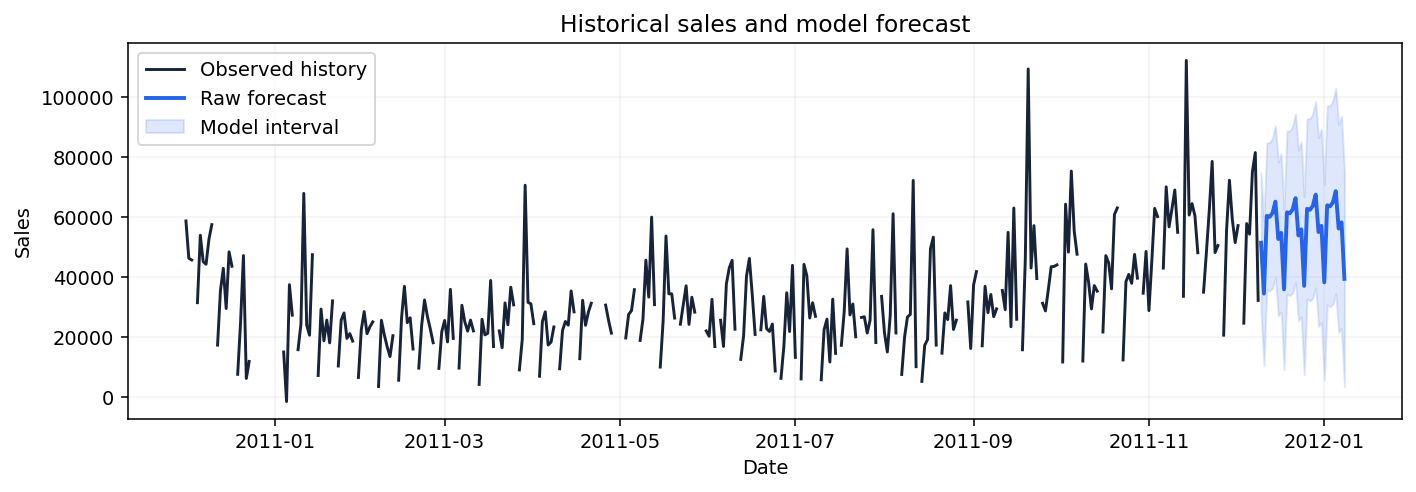

Raw point-forecast total: GBP 1,693,961.86


In [11]:
from src.forecasting.forecast_service import generate_forecast
forecasts = {name: generate_forecast(dataset, configuration, HORIZON, evaluation.metrics_for(name)) for name, configuration in evaluation.configurations.items()}
assert all(run.training_observations == len(dataset.series) and len(run.predictions) == HORIZON for run in forecasts.values())
selected = forecasts[evaluation.best_model]
assert selected.predictions['date'].min() == dataset.series.index[-1] + pd.Timedelta(days=1)
print(f'Selected model: {selected.model}; genuine full-history fits: {list(forecasts)}')
display(selected.predictions)
display(Image(report_history_figure(dataset.observed_series, selected.predictions)))
print(f'Raw point-forecast total: GBP {selected.predictions.prediction.sum():,.2f}')


## 13. Optional grounded Gemini business explanations
Default execution is offline and uses explicitly labelled **Local analytics**. Set `ENABLE_GEMINI = True` to request a live explanation with the official Google SDK. In Colab, the key is requested using hidden `getpass`; locally it can be read server-side from `.env`. Never place a key in a code cell or saved output. The model defaults to the verified `gemini-3.1-flash-lite` and is configurable.

Only aggregate evidence is sent: historical statistics, computed STL diagnostics, common-holdout scores and model-generated forecast summaries. Customer records and identifiers are excluded. Unavailable credentials, quota, network, model or structured responses return the deterministic local explanation while numeric forecasting stays available. Live generation was separately verified by `scripts/run_experiments.py --gemini`; the offline notebook output is not relabelled as Gemini.

In [12]:
from src.ai.gemini_client import GeminiClient
from src.ai.insight_generator import build_analytics_context, generate_insights
ENABLE_GEMINI = False
context = build_analytics_context(dataset, evaluation, selected, seasonal)
key = None if ENABLE_GEMINI else ''
if ENABLE_GEMINI and IS_COLAB and not os.getenv('GEMINI_API_KEY'):
    from getpass import getpass
    key = getpass('Gemini API key (hidden; never saved): ')
with GeminiClient(api_key=key) as client:
    insights = generate_insights(context, client=client)
key = None
print(f'Explanation source: {insights.source}; status: {insights.status}')
display(Markdown(insights.text))
print('Only these aggregate analytics sections are eligible for Gemini:', list(context))


Explanation source: Local analytics; status: missing_key


### Computed analytics summary
- Observed historical sales total **9,747,747.93 GBP** across **305** observed periods.
- Mean period sales are **31,959.83**, with a range from **-1,566.23** to **112,141.11**.
- First-to-latest observed-period growth is **-45.20%**. This is not a causal trend estimate.
- **69** unknown periods used the explicitly selected **ffill** strategy. Imputed targets are excluded from model scoring.
- STL seasonal strength is **0.386** at **7** observations per cycle. Interpret this as descriptive evidence.
- Holdout selection uses the lowest **RMSE**. Best successful model: **SARIMA**.
- **SARIMA** predicts a raw total of **1,693,961.86 GBP** over **30** future periods after full-history retraining.
- Use period uncertainty intervals for scenario review. Revenue forecasts alone cannot determine inventory quantities without product mix, prices and lead times.

This is a deterministic explanation of computed analytics, labeled separately from Gemini-generated insights.

Only these aggregate analytics sections are eligible for Gemini: ['dataset', 'history', 'seasonality', 'evaluation', 'forecast']


## 14. CSV, illustrated PDF, Excel and SQLite history
Export the actual selected forecast and computed report context. SQLite stores aggregate execution snapshots and points, not the raw invoice workbook or credentials. The report includes provenance, cleaning audit, observed statistics, seasonal components, all three real holdout evaluations, final forecast and the correctly labelled explanation source.

In [13]:
from src.database.db_manager import DatabaseManager
from src.reports.report_generator import build_report_context, export_csv, generate_excel_report, generate_pdf_report
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
report = build_report_context(dataset, evaluation, selected, seasonal, insights)
pdf = generate_pdf_report(report)
workbook = generate_excel_report(report)
assert pdf.startswith(b'%PDF-')
assert 'Forecast' in pd.ExcelFile(io.BytesIO(workbook)).sheet_names
(OUTPUT_DIRECTORY / 'selected_forecast.csv').write_bytes(export_csv(selected.predictions))
(OUTPUT_DIRECTORY / 'salesvision_report.pdf').write_bytes(pdf)
(OUTPUT_DIRECTORY / 'salesvision_report.xlsx').write_bytes(workbook)
history_database = DatabaseManager(OUTPUT_DIRECTORY / 'notebook_history.sqlite3')
history_database.save_forecast(selected, report)
display(history_database.list_forecasts())
print(f'Illustrated PDF: {len(pdf):,} bytes; Excel: {len(workbook):,} bytes.')


,Run ID,Executed (UTC),Dataset,Kind,Model,Frequency,Horizon,RMSE,MAE,Result Reference,Fingerprint
0,3389d4381f3541d0b1479a0030251946,2026-11-16T16:26:13.342305+00:00,UCI Online Retail — recorded daily net revenue,real,SARIMA,D,30,16669.56,12076.295975,sqlite:forecast_points/3389d4381f3541d0b1479a0...,c40c7a2d953a48c7c668e979f4b87a011afccf2f6d969a...
1,107ec7af4df0401999f1800bdd278fda,2026-11-16T13:04:21.382190+00:00,UCI Online Retail — recorded daily net revenue,real,SARIMA,D,30,16669.56,12076.295975,sqlite:forecast_points/107ec7af4df0401999f1800...,c40c7a2d953a48c7c668e979f4b87a011afccf2f6d969a...
2,74832b6f4aa741c99397499935d37744,2026-11-16T12:02:59.297592+00:00,UCI Online Retail — recorded daily net revenue,real,SARIMA,D,30,16669.56,12076.295975,sqlite:forecast_points/74832b6f4aa741c99397499...,c40c7a2d953a48c7c668e979f4b87a011afccf2f6d969a...


Illustrated PDF: 636,296 bytes; Excel: 60,986 bytes.


## 15. Actual findings, interpretation and limitations
The following text is built from executed arrays and metrics. It records whether the selected three-model winner beats the stronger naive baseline. Do not substitute an expected winner or invent improvements. Limitations include one retailer, archived dates, retained net returns/duplicates, imputed modelling dates, short yearly-seasonality history, a single final holdout, prespecified parameters, and no labelled future targets. Revenue is not inventory quantity.

In [14]:
display(Markdown(experiment_findings(dataset, evaluation, baselines, forecasts)))
reference_path = ROOT / 'outputs/experiments/uci_daily/model_comparison.csv'
if reference_path.is_file():
    reference = pd.read_csv(reference_path).set_index('Model')
    current = evaluation.comparison.set_index('Model')
    import numpy as np
    np.testing.assert_allclose(current.loc[reference.index, ['MAE', 'RMSE', 'MAPE', 'sMAPE']].to_numpy(dtype=float), reference[['MAE', 'RMSE', 'MAPE', 'sMAPE']].to_numpy(dtype=float), rtol=1e-5, atol=1e-3)
    print('Notebook metrics reproduce the saved script experiment within stated numerical tolerance.')


# Executed UCI Online Retail experiment

Real dataset: UCI Online Retail — recorded daily net revenue (CC BY 4.0; GBP net revenue).
History: 2010-12-01 to 2011-12-09; 305 observed dates in 374 calendar days.
69 unknown days use explicit causal forward-fill for model inputs only. Observed historical totals and scored targets retain the original unknowns.
Observed net revenue: GBP 9,747,747.93.

## Prespecified evaluation

Training: 344 calendar days, ending 2011-11-09.
Common holdout: 30 calendar days, 2011-11-10 to 2011-12-09.
No random split or holdout-directed parameter search was used. The winner is selected among ARIMA, SARIMA and Prophet by lowest valid holdout RMSE.

| Model | MAE (GBP) | RMSE (GBP) | MAPE (%) | sMAPE (%) | Bias (GBP) | Scored dates |
|---|---:|---:|---:|---:|---:|---:|
| ARIMA | 14,384.500 | 19,529.031 | 29.658 | 26.746 | -5,150.079 | 26 |
| SARIMA | 12,076.296 | 16,669.560 | 26.450 | 22.147 | 4,013.102 | 26 |
| Prophet | 12,312.633 | 17,955.768 | 21.492 | 22.147 | -7,436.187 | 26 |

Selected model: **SARIMA**, holdout RMSE **GBP 16,669.560**.
Final SARIMA is refitted on all 374 calendar days. Its 30-day forecast spans 2011-12-10 to 2012-01-08 and has a raw point-forecast total of GBP 1,693,961.86.

## Baseline benchmarks

| Baseline | MAE (GBP) | RMSE (GBP) |
|---|---:|---:|
| Last-value naive | 15,008.011 | 19,868.400 |
| Seven-day seasonal naive | 12,353.891 | 15,328.037 |

The selected model **does not beat** the stronger naive baseline on this holdout. Baselines are benchmarks, not candidates in the application's three-model selection.

## Training-partition rolling-origin results

These separate earlier windows do not replace the final holdout selection.

| Model | RMSE (GBP) | Completed folds | Status |
|---|---:|---:|---|
| ARIMA | 15,668.915 | 3 | success |
| SARIMA | 13,738.304 | 3 | success |
| Prophet | 14,887.998 | 3 | success |

## Interpretation and limits

- This archived dataset represents one UK online retailer; these are not Walmart findings.
- Missing dates are unknown; causal forward-fill is a documented modelling assumption. STL diagnostics also use that filled series and are descriptive, not causal.
- Source returns/cancellations and exact duplicates are retained, so the target is recorded net revenue.
- The final forecast is future relative to the dataset's last date, not a forecast for today's calendar.
- About one year of history does not identify yearly Prophet seasonality; it is explicitly disabled.
- MAPE can be large for small or negative net-sales days; zero targets are excluded only from MAPE.
- Parameters are fixed examples, not proof of globally optimal models; one holdout does not establish general superiority.
- Model-based period intervals are not guaranteed coverage or a joint interval for total revenue.
- Revenue predictions alone cannot determine stock quantities, prices, product mix or lead times.
- No future labelled targets exist for the final forecast; no future accuracy claim is made.

Source: https://archive.ics.uci.edu/dataset/352/online+retail

Citation: Chen, D. (2015). Online Retail. UCI Machine Learning Repository. DOI: 10.24432/C5BW33.


Notebook metrics reproduce the saved script experiment within stated numerical tolerance.


## 16. Reproducibility, artifact manifest and downloads
Save model configurations, versions, seed, fingerprint, all holdout/backtest/future prediction tables, recorded fit summaries, report snapshot, charts and checksums. CLI equivalent: `python scripts/run_experiments.py` (add `--gemini` only for a live explanation). The notebook uses a separate output directory so it preserves the CLI's live-Gemini evidence.

The final ZIP contains generated notebook artifacts for download. The Streamlit application remains independently launchable with `streamlit run app.py`; it does not require a live Colab connection.

In [15]:
import hashlib
manifest = export_experiment(dataset, evaluation, forecasts, seasonal, baselines, insights, OUTPUT_DIRECTORY)
assert manifest['status'] == 'success'
assert all(hashlib.sha256((OUTPUT_DIRECTORY / name).read_bytes()).hexdigest() == artifact['sha256'] for name, artifact in manifest['artifacts'].items())
bundle = OUTPUT_DIRECTORY / 'notebook_results.zip'
with zipfile.ZipFile(bundle, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUTPUT_DIRECTORY.iterdir()):
        if path.is_file() and path != bundle and not path.name.endswith(('-wal', '-shm')):
            archive.write(path, path.name)
print(f'Verified {len(manifest["artifacts"])} artifact checksums; all three models and final forecasts succeeded.')
print(f'Download bundle: {bundle}')
if IS_COLAB:
    from google.colab import files
    files.download(str(bundle))


Verified 37 artifact checksums; all three models and final forecasts succeeded.
Download bundle: D:\Project\MinorProject\sales-forecasting-system\outputs\experiments\uci_daily_notebook\notebook_results.zip
